In [1]:
from slab.instruments import InstrumentManager, SignalCore, voltsource
from slab.instruments.nwa import E5071
from slab.instruments import N5242A
from slab.datamanagement import SlabFile
from slab import *
from numpy import *
import os

No module named 'visa.six.moves'
Warning VISA library import failed
Warning could not load Chase AWG dll, check that dll located at 'C:\_Lib\python\slab\instruments\awg\chase\dax22000_lib_DLL32.dll'
Could not load InstrumentManagerWindow
Warning could not load LDA labbrick dll, check that dll located at 'C:\_Lib\python\slab\instruments\labbrick\VNX_atten.dll'
Warning could not load LMS labbrick dll, check that dll located at 'C:\_Lib\python\slab\instruments\labbrick\vnx_fmsynth.dll'
Warning could not load LPS labbrick dll, check that dll located at 'C:\_Lib\python\slab\instruments\labbrick\VNX_dps.dll'
Could not load labbrick


In [2]:
import pandas as pd
from scipy import optimize, special
from scipy.optimize import curve_fit
from scipy import optimize, special
from numpy import pi, sqrt, ceil, array, sin, cos, tan, arctan, tanh, log, exp
import numpy as np
# from lmfit import Parameters,minimize, fit_report
from scipy import interpolate

# Fitting function

In [3]:
def fitgeneral(xdata, ydata, fitfunc, fitparams, domain=None, showfit=False, showstartfit=False, showdata=True,
               label="", mark_data='bo', mark_fit='r-'):
    """Uses optimize.leastsq to fit xdata ,ydata using fitfunc and adjusting fit params"""
    # sort data
    order = np.argsort(xdata)
    xdata = xdata[order]
    ydata = ydata[order]
    if domain is not None:
        fitdatax,fitdatay = selectdomain(xdata,ydata,domain)
    else:
        fitdatax=xdata
        fitdatay=ydata
#    print 'minimum', np.min(fitdatay)
#    ymin=np.min(fitdatay)
    errfunc = lambda p, x, y: (fitfunc(p,x) - y) #there shouldn't be **2 # Distance to the target function
    startparams=fitparams # Initial guess for the parameters
    bestfitparams, success = optimize.leastsq(errfunc, startparams[:], args=(fitdatax,fitdatay))
    if showfit:
        if showdata:
            plt.plot(fitdatax,fitdatay,mark_data,label=label+" data")
        if showstartfit:
            plt.plot(fitdatax,fitfunc(startparams,fitdatax),label=label+" startfit")
        plt.plot(fitdatax,fitfunc(bestfitparams,fitdatax),mark_fit,label=label+" fit")
        if label!='': plt.legend()
        err=math.fsum(errfunc(bestfitparams,fitdatax,fitdatay))
        #print 'the best fit has an RMS of {0}'.format(err)
#    plt.t
#    plt.figtext()
    return bestfitparams

def fitexp(xdata,ydata,fitparams=None,domain=None,showfit=False,showstartfit=False,label=""):
    """Fit exponential decay (p[0]+p[1]*exp(-(x-p[2])/p[3]))"""
    if domain is not None:
        fitdatax,fitdatay = selectdomain(xdata,ydata,domain)
    else:
        fitdatax=xdata
        fitdatay=ydata
    if fitparams is None:    
        fitparams=[0.,0.,0.,0.]
        fitparams[0]=fitdatay[-1]
        fitparams[1]=fitdatay[0]-fitdatay[-1]
        fitparams[1]=fitdatay[0]-fitdatay[-1]
        fitparams[2]=fitdatax[0]
        fitparams[3]=(fitdatax[-1]-fitdatax[0])/5.
    #print fitparams
    p1 = fitgeneral(fitdatax, fitdatay, expfunc, fitparams, domain=None, showfit=showfit, showstartfit=showstartfit,
                    label=label)
    return p1 

def fitdecaysin(xdata,ydata,fitparams=None,domain=None,showfit=False,showstartfit=False,label=""):
    """Fits decaying sin wave of form: p[0]*np.sin(2.*pi*p[1]*x+p[2]*pi/180.)*np.e**(-1.*(x-p[5])/p[3])+p[4]"""
    if domain is not None:
        fitdatax,fitdatay = selectdomain(xdata,ydata,domain)
    else:
        fitdatax=xdata
        fitdatay=ydata
    if fitparams is None:    
        FFT=scipy.fft(fitdatay)
        fft_freqs=scipy.fftpack.fftfreq(len(fitdatay),fitdatax[1]-fitdatax[0])
        max_ind=np.argmax(abs(FFT[4:int(len(fitdatay)/2)]))+4
        fft_val=FFT[max_ind]
        
        fitparams=[0,0,0,0,0]
        fitparams[4]=np.mean(fitdatay)
        fitparams[0]=(max(fitdatay)-min(fitdatay))/2.#2*abs(fft_val)/len(fitdatay)
        fitparams[1]=fft_freqs[max_ind]
        fitparams[2]=(cmath.phase(fft_val)-np.pi/2.)*180./np.pi
        fitparams[3]=(max(fitdatax)-min(fitdatax))

        #fitparams[5]=fitdatax[0]
        
    decaysin3 = lambda p, x: p[0] * np.sin(2. * np.pi * p[1] * x + p[2] * np.pi / 180.) * np.e ** (
    -1. * (x - fitdatax[0]) / p[3]) + p[4]
    # decaysin3 = lambda p, x: p[0] * np.sin(2. * np.pi * p[1] * x + p[2] - np.pi / 2.) * np.e ** (
    # -1. * (x - fitdatax[0]) / p[3]) + p[4]
    #print "fitparams: ",fitparams
    p1 = fitgeneral(fitdatax, fitdatay, decaysin3, fitparams, domain=None, showfit=showfit, showstartfit=showstartfit,
                    label=label)
    return p1  

def fitsin(xdata,ydata,fitparams=None,domain=None,showfit=False,showstartfit=False,label=""):
    """Fits decaying sin wave of form: p[0]*np.sin(2.*pi*p[1]*x+p[2]*pi/180.)*np.e**(-1.*(x-p[5])/p[3])+p[4]"""
    if domain is not None:
        fitdatax,fitdatay = selectdomain(xdata,ydata,domain)
    else:
        fitdatax=xdata
        fitdatay=ydata
    if fitparams is None:    
        FFT=scipy.fft(fitdatay)
        fft_freqs=scipy.fftpack.fftfreq(len(fitdatay),fitdatax[1]-fitdatax[0])
        max_ind=np.argmax(abs(FFT[4:int(len(fitdatay)/2)]))+4
        fft_val=FFT[max_ind]
        
        fitparams=[0,0,0,0]
        fitparams[3]=np.mean(fitdatay)
        fitparams[0]=(max(fitdatay)-min(fitdatay))/2.#2*abs(fft_val)/len(fitdatay)
        fitparams[1]=fft_freqs[max_ind]
        fitparams[2]=(cmath.phase(fft_val)-np.pi/2.)*180./np.pi

        #fitparams[5]=fitdatax[0]
        
    decaysin3 = lambda p, x: p[0] * np.sin(2. * np.pi * p[1] * x + p[2] * np.pi / 180.) + p[3]
    # decaysin3 = lambda p, x: p[0] * np.sin(2. * np.pi * p[1] * x + p[2] - np.pi / 2.) * np.e ** (
    # -1. * (x - fitdatax[0]) / p[3]) + p[4]
    #print "fitparams: ",fitparams
    p1 = fitgeneral(fitdatax, fitdatay, decaysin3, fitparams, domain=None, showfit=showfit, showstartfit=showstartfit,
                    label=label)
    return p1  

def fitdisplacement(xdata,ydata,fitparams=None,domain=None,showfit=False,showstartfit=False,label=""):
    """Fits decaying sin wave of form: p[0]*(p[1]/((x-p[2])^2+p[1]^2))+p[3]*(p[4]/((x-p[5])^2+p[4]^2))+p[6]*(p[7]/((x-p[8])^2+p[7]^2))+p[9]"""
    if domain is not None:
        fitdatax,fitdatay = selectdomain(xdata,ydata,domain)
    else:
        fitdatax=xdata
        fitdatay=ydata
    if fitparams is None:    
        FFT=scipy.fft(fitdatay)
        fft_freqs=scipy.fftpack.fftfreq(len(fitdatay),fitdatax[1]-fitdatax[0])
        max_ind=np.argmax(abs(FFT[4:int(len(fitdatay)/2)]))+4
        fft_val=FFT[max_ind]
        
        fitparams=[0,0,0,0,0,0,0]
        # fitparams[4]=np.mean(fitdatay)
        # fitparams[0]=(max(fitdatay)-min(fitdatay))/2.#2*abs(fft_val)/len(fitdatay)
        # fitparams[1]=fft_freqs[max_ind]
        # fitparams[2]=(cmath.phase(fft_val)-np.pi/2.)*180./np.pi
        # fitparams[3]=(max(fitdatax)-min(fitdatax))

        #fitparams[5]=fitdatax[0]
        
    dis3 = lambda p, x: p[0] * (p[1]/((x-p[2])**2)+p[1]**2)+ p[3] * (p[4]/((x-p[5])**2)+p[4]**2)+p[6]
    #print "fitparams: ",fitparams
    p1 = fitgeneral(fitdatax, fitdatay, dis3, fitparams, domain=None, showfit=showfit, showstartfit=showstartfit,
                    label=label)
    return p1  

In [4]:
def fitamp(p1, p2):
    fitamparray = []
    fitfreqarray = []
    
    fitamparray_err = []
    fitfreqarray_err = []

    n_peaks = int((len(p1)-1)/3)
    for i in range(n_peaks):
        fitamparray.append(p1[3*i+1])
        fitfreqarray.append(p1[3*i+2])
        fitamparray_err.append(np.sqrt(np.diag(p2)[3*i+1]))
        fitfreqarray_err.append(np.sqrt(np.diag(p2)[3*i+2]))
        
    return fitamparray , fitfreqarray, fitamparray_err, fitfreqarray_err
def gaussfuncsum_with_baseline(x, *args):
    """p[0]+p[1]/(1+(x-p[2])**2/p[3]**2)"""
    y = 0 
    p = args
#     print(len(p))
    for ii in range(N):
        y = y + p[3*ii+1]*exp(-(x-p[3*ii+2])**2/(2*p[3*ii+3]**2))
    y += p[0]
    return y

def fitgausssum_with_baseline(xdata, ydata, fitparams=None):
    """fit lorentzian:
        returns [offset,amplitude,center,hwhm]"""
    fitdatax = xdata
    fitdatay = ydata        
    popt, pcov = curve_fit(gaussfuncsum_with_baseline, fitdatax, fitdatay, p0=fitparams)

    return popt, pcov
def gauss_baseline(x, *p):
    return p[0] + p[1]*np.exp(-(x-p[2])**2/(2*p[3]**2))
def coherent_state(n, alpha):
    return np.exp(-abs(alpha)**2)*abs(alpha)**(2*n)/scipy.special.factorial(n)
def number_splitting(x, y, n=0, plot=False):
    """Fits an individual Gaussian around each number peak and returns an array
    of the peak values and frequency with error bars.
    'x': in units of χ so please pass it correctly, >0
    'y': qubit excitation probability
    """
    # number of peaks
    num_peaks = int(max(x)+1)
    
    fitdata = {}
    peaks = []
    freqs = []
    peaks_err = []
    freqs_err = []
    if plot:
        fig, axs = plt.subplots(1, 1, dpi=300)
        plt.tight_layout()
        axs.set_xlabel(r'$n$', fontsize=20)
        axs.set_ylabel(r'$P_{e}$', fontsize=20)
        axs.grid(True, which='major', axis='both', color='grey', linestyle='--', linewidth=0.4)
        plt.tick_params(direction='in', length=6, width=2, colors='k', \
            grid_color='grey', grid_alpha=0.5, labelsize=20, labelbottom=True, right=True, top=True, left=True)
    
    for ind in range(num_peaks-n):
#         fitdata['n%.i'%ind] = {}
        """Fits the peak with a Gaussian spanning 1 unit of χ"""
        min_ind, max_ind =  np.argmin(abs(x-ind-0.5)), np.argmin(abs(x-ind+0.5))

        x_domain = x[min_ind:max_ind]
        y_domain = y[min_ind:max_ind]
        
        a = (y_domain[0] + y_domain[-1])/2
        b = (np.max(y_domain) - np.min(y_domain))
        c = x_domain[np.argmax(y_domain)]
        d = (np.max(x_domain) - np.min(x_domain))/4
        p = [a, b, c, d]
        popt, pcov = curve_fit(gauss_baseline, x_domain, y_domain, p0=(a, b, c, d))
        if plot:
            axs.plot(x_domain, y_domain, 'ks')
            axs.plot(x_domain, gauss_baseline(x_domain, *popt), 'r')
        
        freqs.append(popt[2])
        freqs_err.append(np.sqrt(np.diag(pcov)[2]))
        peaks.append(popt[1])
        peaks_err.append(np.sqrt(np.diag(pcov)[1]))
        
    fitdata['freq'] = freqs
    fitdata['peak'] = peaks
    fitdata['freq_err'] = freqs_err
    fitdata['peak_err'] = peaks_err
    if plot:
        plt.show()
    """Note: Don't forget to scale the returned frequency values with χ """
    return fitdata

def fitcoherentstate(peak_val, peak_val_err=0):
    xdata = np.arange(len(peak_val))
    ydata = np.array(peak_val)
    if peak_val_err:
        ydata_err = np.array(peak_val_err)
        popt, pcov = curve_fit(coherent_state, xdata, ydata, sigma=ydata_err)
    else:
        popt, pcov = curve_fit(coherent_state, xdata, ydata)

    return popt[0], np.sqrt(pcov[0][0])

# Analysis function

In [5]:
def parity_measurement_avg_plot(xpts, ydata, ylimit=[-20,10]):
    plt.figure(figsize = (10,4))
    plt.title("Parity measurement")
    plt.plot(xpts,ydata)
    plt.xlabel("Readout")
    plt.ylabel("Measurement counts")
    plt.ylim(ylimit)
def parity_measurement_plot(xpts, ydata, ylimit=[-20,10]):
    plt.figure(figsize = (10,4))
    plt.title("Parity measurement")
    plt.plot(xpts,ydata)
    plt.xlabel("Readout")
    plt.ylabel("Measurement counts")
    plt.ylim(ylimit)
def custom_average(arr1d,avg_count):
    if avg_count>1:
        arr1d = np.mean(arr1d.reshape((avg_count, int(len(arr1d)/avg_count))), axis=0)
    return arr1d
def hist_gef(data=None, plot=True, ran=100.0):
    ig = data[0]
    qg = data[1]
    ie = data[2]
    qe = data[3]
    i_f = data[4]
    qf = data[5]

    numbins = 200

    xg, yg = np.median(ig), np.median(qg)
    xe, ye = np.median(ie), np.median(qe)
    xf, yf = np.median(i_f), np.median(qf)

    if plot == True:
        fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))
        fig.tight_layout()

        axs[0].scatter(ig, qg, label='g', color='b', marker='*')
        axs[0].scatter(ie, qe, label='e', color='r', marker='*')
        axs[0].scatter(i_f, qf, label='f', color='g', marker='*')
        axs[0].scatter(xg, yg, color='k', marker='o')
        axs[0].scatter(xe, ye, color='k', marker='o')
        axs[0].scatter(xf, yf, color='k', marker='o')
        axs[0].set_xlabel('I (a.u.)')
        axs[0].set_ylabel('Q (a.u.)')
        axs[0].legend(loc='upper right')
        axs[0].set_title('Unrotated')
        axs[0].axis('equal')
    """Compute the rotation angle"""
    theta_ge = -np.arctan2((ye - yg), (xe - xg))
    theta_ef = -np.arctan2((yf - ye), (xf - xe))
    theta = theta_ge
    if plot:
        print(theta_ge, theta_ef)
#     theta_gf = -np.arctan2((yf - yg), (xf - xg))
    """Rotate the IQ data"""
    ig_new = ig * np.cos(theta) - qg * np.sin(theta)
    qg_new = ig * np.sin(theta) + qg * np.cos(theta)
    ie_new = ie * np.cos(theta) - qe * np.sin(theta)
    qe_new = ie * np.sin(theta) + qe * np.cos(theta)
    if_new = i_f * np.cos(theta) - qf * np.sin(theta)
    qf_new = i_f * np.sin(theta) + qf * np.cos(theta)

    """New means of each blob"""
    xg, yg = np.median(ig_new), np.median(qg_new)
    xe, ye = np.median(ie_new), np.median(qe_new)
    xf, yf = np.median(if_new), np.median(qf_new)

    # print(xg, xe)

    xlims = [xg - ran, xg + ran]
    ylims = [yg - ran, yg + ran]

    if plot == True:
        axs[1].scatter(ig_new, qg_new, label='g', color='b', marker='*')
        axs[1].scatter(ie_new, qe_new, label='e', color='r', marker='*')
        axs[1].scatter(if_new, qf_new, label='f', color='g', marker='*')
        axs[1].scatter(xg, yg, color='k', marker='o')
        axs[1].scatter(xe, ye, color='k', marker='o')
        axs[1].scatter(xf, yf, color='k', marker='o')
        axs[1].set_xlabel('I (a.u.)')
        axs[1].legend(loc='lower right')
        axs[1].set_title('Rotated')
        axs[1].axis('equal')

        """X and Y ranges for histogram"""

        ng, binsg = np.histogram(ig_new, bins=numbins, range=xlims)
        ne, binse = np.histogram(ie_new, bins=numbins, range=xlims)
        nf, binsf = np.histogram(if_new, bins=numbins, range=xlims)
        
        state1_hist_cumsum = np.cumsum(ng)
        state2_hist_cumsum = np.cumsum(ne)
        state3_hist_cumsum = np.cumsum(nf)
        
        axs[2].set_title("Histogram: ")
        axs[2].plot(binsg[:-1],ng, 'b', label='|g>')
        axs[2].plot(binse[:-1],ne, 'r', label='|e>')
        axs[2].plot(binse[:-1],nf, 'g', label='|f>')
#         axs[2].plot(state3_bins[:-1],state3_hist, 'g', label=expt_cfg['states'][state3_ind])
        axs[2].legend()
    #        axs[2].set_xlabel('I(a.u.)')

    else:
        ng, binsg = np.histogram(ig_new, bins=numbins, range=xlims)
        ne, binse = np.histogram(ie_new, bins=numbins, range=xlims)
        nf, binsf = np.histogram(if_new, bins=numbins, range=xlims)

    """Compute the fidelity using overlap of the histograms"""
    contrast_ge = np.abs(((np.cumsum(ng) - np.cumsum(ne)) / (0.5 * ng.sum() + 0.5 * ne.sum())))
    tind_ge = contrast_ge.argmax()
    threshold_ge = binsg[tind_ge]
    fid_ge = contrast_ge[tind_ge]
    
    contrast_ef = np.abs(((np.cumsum(ne) - np.cumsum(nf)) / (0.5 * ne.sum() + 0.5 * nf.sum())))
    tind_ef = contrast_ef.argmax()
    threshold_ef = binse[tind_ef]
    fid_ef = contrast_ef[tind_ef]
    
    contrast_gf = np.abs(((np.cumsum(ng) - np.cumsum(nf)) / (0.5 * ng.sum() + 0.5 * nf.sum())))
    tind_gf = contrast_gf.argmax()
    threshold_gf = binsg[tind_gf]
    fid_gf = contrast_gf[tind_gf]
    # axs[2].set_title(f"Fidelity = {fid*100:.2f}%")
    fid = [fid_ge, fid_ef, fid_gf]
    threshold = [threshold_ge, threshold_ef, threshold_gf]

    return fid, threshold, theta
    
def histogram_analysis(data1, plot=True):
    fid, threshold, angle = hist_gef(data=[data1['g_i'], data1['g_q'], data1['e_i'], data1['e_q'], data1['f_i'], data1['f_q']], plot=plot, ran=2000)

    
    if plot:
        plt.tight_layout()
        plt.show()
        print("fidelity:", fid)
        print("angle:", -angle*180/np.pi)
        print("threshold:", threshold)
    return fid, -angle*180/np.pi, threshold
                           
                            
        
def plot_echo(x_time, y_data, pi_length=50, t1=1000, t2=1000, hlines=None, vlines=None):
    plt.figure(figsize = (10,4))
    plt.title("Echo of qubit" )
    y = y_data
    plt.plot(x_time,y_data)
    fitguess = [max(y)/2-min(y)/2, 1/(2*pi_length), 0, t2, max(y)/2+min(y)/2]
    fitdata = fitdecaysin(x_time[:],y_data[:],fitparams = fitguess,showfit=True)
    plt.text(0.8, 0.8, "Decay = %.3f us" \
             %(fitdata[3]), fontsize=12)
    if vlines is not None:
        for vline in vlines:
            plt.axvline(vline, color='g', ls='--')
    if hlines is not None:
        for hline in hlines:
            plt.axhline(hline, color='g', ls='--')
    print("Oscillation frequency: %s MHz" %str(fitdata[1]))
    print('Dephasing Time: %s us' %(fitdata[3]))
    
def plot_t1(x_time, y_data,T1guess=10):
    plt.figure(figsize = (10,4))
    plt.title("T1 experiment" )
    plt.plot(x_time,y_data)
    fitguess = [min(y_data), max(y_data)-min(y_data),0,T1guess]
    fitdata = fitexp(x_time, y_data, fitparams=fitguess, showfit=True)
    plt.text(max(x_time)/2+min(x_time)/2, max(y_data)/2+min(y_data)/2, "Decay = %.2f us"%(fitdata[3]), fontsize=12)
    print('Decay Time: %s us' %(fitdata[3]))
def plot_amp_rabi(amp_x, signal_y, pi_length=100, t1=1000, vlines=None, hlines=None):
    plt.figure(figsize = (10,4))
    plt.title("Amplitude Rabi")
    plt.plot(amp_x,signal_y)
    plt.xlabel("Gain")
    y = signal_y
    fitguess = [max(y)/2-min(y)/2, 1/(2*pi_length), 0, t1, max(y)/2+min(y)/2]
    fitdata = fitdecaysin(amp_x,signal_y,fitparams = fitguess,showfit=True)
#         plt.ylim(-0.1,1.1)
    pi_length = (90.0-fitdata[2])/(360.0*fitdata[1])
    pi_length1 = pi_length
    if pi_length1>0:
        while pi_length1>0:
            pi_length1 -=abs(180/360.0/fitdata[1])
        pi_length1 += abs(180/360.0/fitdata[1])
    else:
        while pi_length1<0:
            pi_length1 +=abs(180/360.0/fitdata[1])
    pi_length11 = pi_length1 +abs(180/360.0/fitdata[1])
    comparea = fitdata[0]*np.sin(2*np.pi*fitdata[1]*pi_length1+fitdata[2]*np.pi/180)*np.exp(-(pi_length1-amp_x[0])/fitdata[3])+fitdata[4]
    compareb = fitdata[0]*np.sin(2*np.pi*fitdata[1]*pi_length11+fitdata[2]*np.pi/180)*np.exp(-(pi_length11-amp_x[0])/fitdata[3])+fitdata[4]
    if abs(compareb)>abs(comparea): pi_length1 = pi_length11
    hpi_length = pi_length1-abs(180/360.0/fitdata[1])/2
    print('auto pi_len: %.2f' %(pi_length1))
    print('auto pi/2_len: %.2f' %(hpi_length))
    print('pi len: %.2f or %.2f or %.2f or %.2f' %(pi_length, (270.0-fitdata[2])/(360.0*fitdata[1]), 2*pi_length-(270.0-fitdata[2])/(360.0*fitdata[1]), 2*(270.0-fitdata[2])/(360.0*fitdata[1])-pi_length))
    print('pi/2 len: %.2f or %.2f' %(pi_length-1/fitdata[1]/4, (270.0-fitdata[2])/(360.0*fitdata[1])-1/fitdata[1]/4))
#         plt.axvline(1*pi_length)
    if vlines is not None:
        for vline in vlines:
            plt.axvline(vline, color='g', ls='--')
    if hlines is not None:
        for hline in hlines:
            plt.axhline(hline, color='g', ls='--')
#     print('Oscillation rate is:',1000*fitdata[1],'MHz')
    print('Oscillation amp is:',fitdata[0])
#     print('Decay Time: %s ns' %(fitdata[3]))

def plot_length_rabi(len_x, signal_y, pi_length=100, t1=1000, vlines=None, hlines=None):
    plt.figure(figsize = (10,4))
    plt.title("Length Rabi")
    plt.plot(len_x,signal_y)
    plt.xlabel("Time(us)")
    y = signal_y
    fitguess = [max(y)/2-min(y)/2, 1/(2*pi_length), 0, t1, max(y)/2+min(y)/2]
    fitdata = fitdecaysin(len_x,signal_y,fitparams = fitguess,showfit=True)
#         plt.ylim(-0.1,1.1)
    pi_length = (90.0-fitdata[2])/(360.0*fitdata[1])
    pi_length1 = pi_length
    if pi_length1>0:
        while pi_length1>0:
            pi_length1 -=abs(180/360.0/fitdata[1])
        pi_length1 += abs(180/360.0/fitdata[1])
    else:
        while pi_length1<0:
            pi_length1 +=abs(180/360.0/fitdata[1])
    pi_length11 = pi_length1 +abs(180/360.0/fitdata[1])
    comparea = fitdata[0]*np.sin(2*np.pi*fitdata[1]*pi_length1+fitdata[2]*np.pi/180)*np.exp(-(pi_length1-len_x[0])/fitdata[3])+fitdata[4]
    compareb = fitdata[0]*np.sin(2*np.pi*fitdata[1]*pi_length11+fitdata[2]*np.pi/180)*np.exp(-(pi_length11-len_x[0])/fitdata[3])+fitdata[4]
    if abs(compareb)>abs(comparea): pi_length1 = pi_length11
    hpi_length = pi_length1-abs(180/360.0/fitdata[1])/2
    print('auto pi_len: %.5f' %(pi_length1))
    print('auto pi/2_len: %.5f' %(hpi_length))
    print('pi len: %.5f or %.5f or %.5f or %.5f' %(pi_length, (270.0-fitdata[2])/(360.0*fitdata[1]), 2*pi_length-(270.0-fitdata[2])/(360.0*fitdata[1]), 2*(270.0-fitdata[2])/(360.0*fitdata[1])-pi_length))
    print('pi/2 len: %.5f or %.5f' %(pi_length-1/fitdata[1]/4, (270.0-fitdata[2])/(360.0*fitdata[1])-1/fitdata[1]/4))
#         plt.axvline(1*pi_length)
    if vlines is not None:
        for vline in vlines:
            plt.axvline(vline, color='g', ls='--')
    if hlines is not None:
        for hline in hlines:
            plt.axhline(hline, color='g', ls='--')
    print('Oscillation rate is:',fitdata[1],'MHz')
    print('Oscillation amp is:',fitdata[0])
    print('Decay Time: %s us' %(fitdata[3]))
    
def plot_length_sideband(len_x, signal_y, pi_length=100, t1=1000, vlines=None, hlines=None):
    plt.figure(figsize = (10,4))
    plt.title("Length sideband")
    plt.plot(len_x,signal_y)
    plt.xlabel("Time(us)")
    y = signal_y
    fitguess = [max(y)/2-min(y)/2, 1/(2*pi_length), 0, t1, max(y)/2+min(y)/2]
    fitdata = fitdecaysin(len_x,signal_y,fitparams = fitguess,showfit=True)
#         plt.ylim(-0.1,1.1)
    pi_length = (90.0-fitdata[2])/(360.0*fitdata[1])
    pi_length1 = pi_length
    if pi_length1>0:
        while pi_length1>0:
            pi_length1 -=abs(180/360.0/fitdata[1])
        pi_length1 += abs(180/360.0/fitdata[1])
    else:
        while pi_length1<0:
            pi_length1 +=abs(180/360.0/fitdata[1])
    pi_length11 = pi_length1 +abs(180/360.0/fitdata[1])
    comparea = fitdata[0]*np.sin(2*np.pi*fitdata[1]*pi_length1+fitdata[2]*np.pi/180)*np.exp(-(pi_length1-len_x[0])/fitdata[3])+fitdata[4]
    compareb = fitdata[0]*np.sin(2*np.pi*fitdata[1]*pi_length11+fitdata[2]*np.pi/180)*np.exp(-(pi_length11-len_x[0])/fitdata[3])+fitdata[4]
    if abs(compareb)>abs(comparea): pi_length1 = pi_length11
    hpi_length = pi_length1-abs(180/360.0/fitdata[1])/2
    print('auto pi_len: %.5f' %(pi_length1))
    print('auto pi/2_len: %.5f' %(hpi_length))
    print('pi len: %.5f or %.5f or %.5f or %.5f' %(pi_length, (270.0-fitdata[2])/(360.0*fitdata[1]), 2*pi_length-(270.0-fitdata[2])/(360.0*fitdata[1]), 2*(270.0-fitdata[2])/(360.0*fitdata[1])-pi_length))
    print('pi/2 len: %.5f or %.5f' %(pi_length-1/fitdata[1]/4, (270.0-fitdata[2])/(360.0*fitdata[1])-1/fitdata[1]/4))
#         plt.axvline(1*pi_length)
    if vlines is not None:
        for vline in vlines:
            plt.axvline(vline, color='g', ls='--')
    if hlines is not None:
        for hline in hlines:
            plt.axhline(hline, color='g', ls='--')
    print('Oscillation rate is:',fitdata[1],'MHz')
    print('Oscillation amp is:',fitdata[0])
    print('Decay Time: %s us' %(fitdata[3]))

def plot_ramsey(x_length, y_data, freq, ramsey_freq, pi_length=100, t2=1000, t1=1000, vline=None, hline=None):
    plt.figure(figsize = (10,4))
    plt.title("Ramsey of qubit " )
    plt.plot(x_length,y_data)
    if vline is not None: plt.axvline(vline, color='g', ls='--')
    if hline is not None: plt.axhline(hline, color='g', ls='--')
    fitguess = [max(y_data)/2-min(y_data)/2, 1/(2*pi_length), 0, t2, \
                max(y_data)/2+min(y_data)/2]
    fitdata = fitdecaysin(x_length,y_data,fitparams = fitguess,showfit=True)
    
    qubit_freq=freq
    print(fitdata)
    real_qubit_freq=qubit_freq + ramsey_freq - fitdata[1]
    possible_qubit_freq=qubit_freq + ramsey_freq + fitdata[1]
    plt.text(0.3, 0.3, "Decay = %.3f us"%(fitdata[3]), fontsize=12)
    print('====qubit information====' )
    print('original qubit frequency:' + str(qubit_freq)+ " MHz")
    print('Ramsey frequency:' +str(ramsey_freq))
    print('Dephasing Time: %s us' %(fitdata[3]))
    print("Oscillation frequency: %s MHz" %str(fitdata[1]))
    print("Suggested qubit frequency: %s MHz" %str(real_qubit_freq))
    print("possible qubit frequency: %s MHz"%str(possible_qubit_freq))
def qubit_temp_analysis(xpts, rabiy1, rabiy2, freq, pi_length=[100,100], t1=[10,10]):
    def temperature_q(nu, rat):
        Kb = 1.38e-23
        h = 2 * np.pi * 1.054e-34
        return h * nu / (Kb * np.log(1 / rat))

    def occupation_q(nu, T):
        Kb = 1.38e-23
        h = 2 * np.pi * 1.054e-34
        return 1 / (np.exp(h * nu / (Kb * T)) + 1)
    rabi_amp1 = 0
    plt.figure(figsize = (10,4))
    plt.title("Rabi1")
    plt.plot(xpts,rabiy1)
    plt.xlabel("Time(us)")
    y = rabiy1
    fitguess = [max(y)/2-min(y)/2, 1/(2*pi_length[0]), 0, t1[0], max(y)/2+min(y)/2]
    fitdata = fitdecaysin(xpts,y,fitparams = fitguess,showfit=True)
    rabi_amp1 = fitdata[0]
    print('Rabi amp1 : %.5f' %(rabi_amp1))
    
    rabi_amp2 = 0
    plt.figure(figsize = (10,4))
    plt.title("Rabi2")
    plt.plot(xpts,rabiy2)
    plt.xlabel("Time(us)")
    y = rabiy2
    fitguess = [max(y)/2-min(y)/2, 1/(2*pi_length[1]), 0, t1[1], max(y)/2+min(y)/2]
    fitdata = fitdecaysin(xpts,y,fitparams = fitguess,showfit=True)
    rabi_amp2= fitdata[0]
    print('Rabi amp2 : %.5f' %(rabi_amp2))
    
    nu_q = freq
    ratio = abs(rabi_amp2 / rabi_amp1)
    print("ge contrast ratio from I data = ", ratio)
    print("Qubit Temp:", 1e3 * temperature_q(nu_q * 1e6, ratio), " mK")
    print("Qubit Excited State Occupation:", occupation_q(nu_q, temperature_q(nu_q, ratio)))

def plot_sideband_sweep(x_timelist, y_freqlist, z_datalist, hlines=None, vlines=None, title="Sideband Sweep"):
    plt.figure(figsize = (15,6))
    plt.subplot(111,xlabel='Time (us)',ylabel='Drive freq (MHz)')
    plt.title(title)
    plt.pcolormesh(x_timelist,y_freqlist[:z_datalist.shape[0]],z_datalist)
    cbar = plt.colorbar()
    if vlines is not None:
        for vline in vlines:
            plt.axvline(vline, color='r', ls='--')
    if hlines is not None:
        for hline in hlines:
            plt.axhline(hline, color='r', ls='--')

# Function to do analysis

In [6]:
def state_allocation(ilist, qlist, angle, threshold):
    # 0=|g>, 1=|e>
    state_list = []
    merged_iq = []
    for ii in range(len(ilist)):
        now = ilist[ii] * np.cos(angle) - qlist[ii] * np.sin(angle)
        merged_iq.append(now)
        if now<threshold:
            state_list.append(0)
        else:
            state_list.append(1)
    return state_list
def parity_measurement_allocation(idata, qdata, angle, threshold, cavity_freq, parity_number):
    dict_list = {}
    dict_list[cavity_freq] = []
    xpts = np.arange(0,parity_number+1,1)
    y_repeat = len(idata[0])
    for ii in range(y_repeat):
        ilist = []
        qlist = []
        for jj in xpts:
            ilist.append(idata[jj][ii])
            qlist.append(qdata[jj][ii])
        state_list = state_allocation(ilist, qlist, angle, threshold)
        dict_list[cavity_freq].append(state_list)
    return dict_list

In [28]:
path = r'Z:\_Data\230430_Tuner_BluFors2\DM_tuning'
file = path+"\Storage _T1-bias (1).xlsx"

result = pd.read_excel(file)

print('Data keys:',result.keys())

flux = result['Flux_quanta'].tolist()
storage_freq = result['Storage frequency'].tolist()
twochi = result['2Chi of storage and qubit'].tolist()
storage_Q = result['Q (million)'].tolist()
storage_t1 = result['storage T1'].tolist()

# linearize the data if having nan
for ii in range(len(twochi)):
    if not(abs(twochi[ii]>0)):
        if ii == len(twochi)-1:
            twochi[ii] = twochi[ii-1]
        else:
            twochi[ii]=(twochi[ii-1]+twochi[ii+1])/2

Data keys: Index(['Unnamed: 0', 'Flux ', 'Flux_quanta', 'Storage frequency', 'storage T1',
       'Q (million)', 'Storage T2', 'Qubit ge', 'Qubit resolved',
       '2Chi of storage and qubit', 'Qubit T1', 'Qubit T2', 'Qubit T2echo',
       'f0g1'],
      dtype='object')


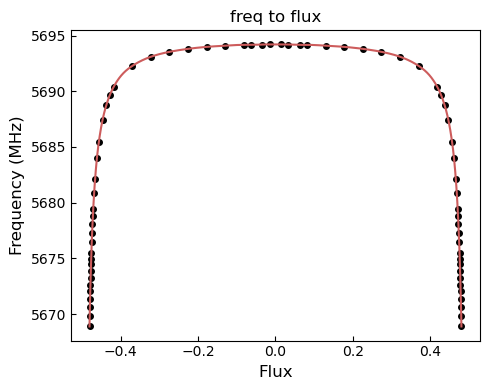

In [29]:
# Step 1: Reverse the list
flux_reversed = flux[::-1]

# Step 2: Change the sign of each element in the reversed list
flux_reversed_neg = [-x for x in flux_reversed]

# Step 3: Append the modified list to the original list
flux_new = flux + flux_reversed_neg

storage_freq_new = storage_freq+storage_freq[::-1]

freq_interpolate = interpolate.interp1d(flux_new, storage_freq_new, kind='cubic',fill_value="extrapolate")
f = np.linspace(flux[-1], -flux[-1], 4001)
ynew = freq_interpolate(f)

fig, ax = plt.subplots(figsize=(5,4))
ax1 = ax
ax1.plot(flux_new, storage_freq_new, 'o',markersize=4, linewidth=1, color = 'k');
ax1.plot(f, ynew, '-',markersize=4, linewidth=1.5, color = 'indianred');
ax1.set_xlabel(r'Flux', fontsize=12, fontname="DejaVu Sans");
ax1.set_ylabel(r'Frequency (MHz)', fontsize=12, fontname="DejaVu Sans");
ax1.set_title('freq to flux')
plt.tight_layout();
plt.show()

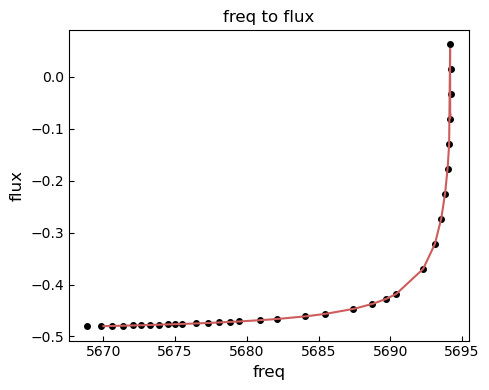

In [30]:
freq2flux_interpolate = interpolate.interp1d(storage_freq, flux, kind='linear',fill_value="extrapolate")
f = np.linspace(5670, 5694.18, 4001)
ynew = freq2flux_interpolate(f)

fig, ax = plt.subplots(figsize=(5,4))
ax1 = ax
ax1.plot(storage_freq, flux, 'o',markersize=4, linewidth=1, color = 'k');
ax1.plot(f, ynew, '-',markersize=4, linewidth=1.5, color = 'indianred');
ax1.set_xlabel(r'freq', fontsize=12, fontname="DejaVu Sans");
ax1.set_ylabel(r'flux', fontsize=12, fontname="DejaVu Sans");
ax1.set_title('freq to flux')
plt.tight_layout();
plt.show()

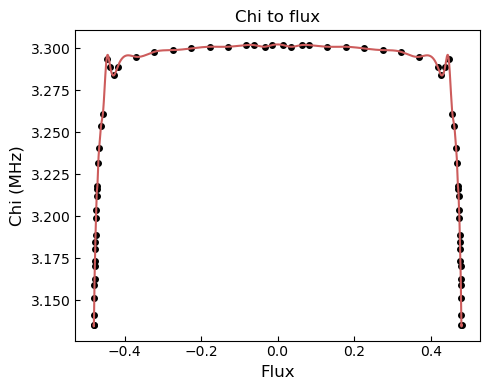

In [35]:


twochi_new = twochi+twochi[::-1]
chi_interpolate = interpolate.interp1d(flux_new, twochi_new, kind='cubic',fill_value="extrapolate")
f = np.linspace(flux[-1], -flux[-1], 4001)
ynew = chi_interpolate(f)

fig, ax = plt.subplots(figsize=(5,4))
ax1 = ax
ax1.plot(flux_new, twochi_new, 'o',markersize=4, linewidth=1, color = 'k');
ax1.plot(f, ynew, '-',markersize=4, linewidth=1.5, color = 'indianred');
ax1.set_xlabel(r'Flux', fontsize=12, fontname="DejaVu Sans");
ax1.set_ylabel(r'Chi (MHz)', fontsize=12, fontname="DejaVu Sans");
ax1.set_title('Chi to flux')
plt.tight_layout();
plt.show()

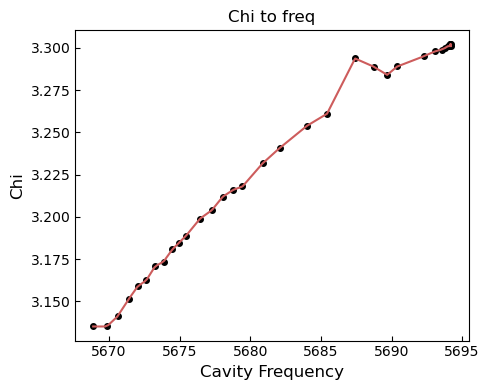

In [36]:
Q_interpolate = interpolate.interp1d(freq_interpolate(flux), twochi, kind='linear',fill_value="extrapolate")
f = np.linspace(flux[0], flux[-1], 4001)
ynew = Q_interpolate(freq_interpolate(f))

fig, ax = plt.subplots(figsize=(5,4))
ax1 = ax
ax1.plot(freq_interpolate(flux), twochi, 'o',markersize=4, linewidth=1, color = 'k');
ax1.plot(freq_interpolate(f), ynew, '-',markersize=4, linewidth=1.5, color = 'indianred');
ax1.set_xlabel(r'Cavity Frequency', fontsize=12, fontname="DejaVu Sans");
ax1.set_ylabel(r'Chi', fontsize=12, fontname="DejaVu Sans");
ax1.set_title('Chi to freq')
plt.tight_layout();
plt.show()

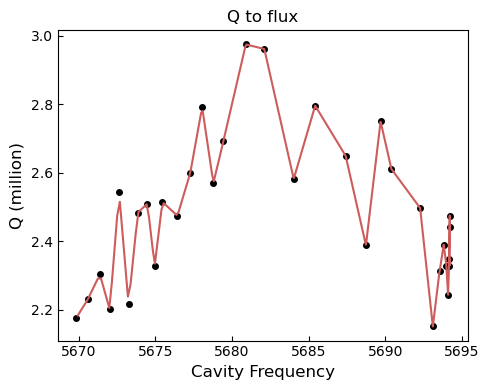

In [34]:
Q_interpolate = interpolate.interp1d(freq_interpolate(flux), storage_Q, kind='linear',fill_value="extrapolate")
f = np.linspace(flux[0], flux[-1], 4001)
ynew = Q_interpolate(freq_interpolate(f))

fig, ax = plt.subplots(figsize=(5,4))
ax1 = ax
ax1.plot(freq_interpolate(flux), storage_Q, 'o',markersize=4, linewidth=1, color = 'k');
ax1.plot(freq_interpolate(f), ynew, '-',markersize=4, linewidth=1.5, color = 'indianred');
ax1.set_xlabel(r'Cavity Frequency', fontsize=12, fontname="DejaVu Sans");
ax1.set_ylabel(r'Q (million)', fontsize=12, fontname="DejaVu Sans");
ax1.set_title('Q to flux')
plt.tight_layout();
plt.show()

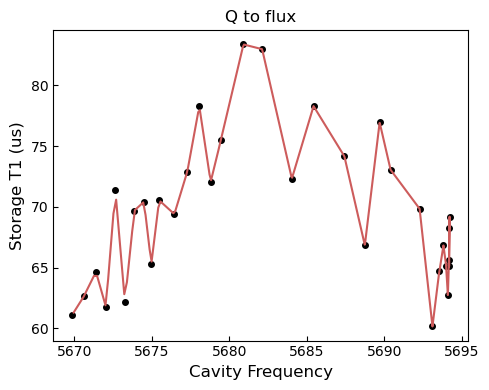

In [35]:
T1_interpolate = interpolate.interp1d(freq_interpolate(flux), storage_t1, kind='linear',fill_value="extrapolate")
f = np.linspace(flux[0], flux[-1], 4001)
ynew = T1_interpolate(freq_interpolate(f))

fig, ax = plt.subplots(figsize=(5,4))
ax1 = ax
ax1.plot(freq_interpolate(flux), storage_t1, 'o',markersize=4, linewidth=1, color = 'k');
ax1.plot(freq_interpolate(f), ynew, '-',markersize=4, linewidth=1.5, color = 'indianred');
ax1.set_xlabel(r'Cavity Frequency', fontsize=12, fontname="DejaVu Sans");
ax1.set_ylabel(r'Storage T1 (us)', fontsize=12, fontname="DejaVu Sans");
ax1.set_title('Q to flux')
plt.tight_layout();
plt.show()

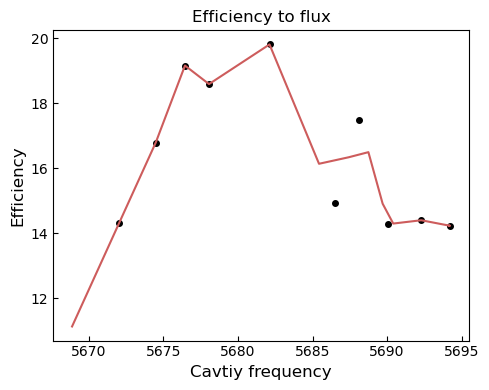

In [36]:
# Detector efficiency
flux_eff = [0, -0.3701923, -0.4230769, -0.4423077, -0.4519231, -0.4615385, -0.4663462, -0.4730769, -0.475, -0.4769231, -0.4788462]
eff = [14.23, 14.4, 14.28, 17.49, 14.92, 6.81, 19.81, 18.59, 19.16, 16.79, 14.31]

flux_eff = [0, -0.3701923, -0.4230769, -0.4423077, -0.4519231, -0.4663462, -0.4730769, -0.475, -0.4769231, -0.4788462]
eff = [14.23, 14.4, 14.28, 17.49, 14.92, 19.81, 18.59, 19.16, 16.79, 14.31]


eff_interpolate = interpolate.interp1d(freq_interpolate(flux_eff), eff, kind='linear',fill_value="extrapolate")
# f = np.linspace(flux[0], flux[-1], 4001)
ynew = eff_interpolate(storage_freq)

fig, ax = plt.subplots(figsize=(5,4))
ax1 = ax
ax1.plot(freq_interpolate(flux_eff), eff, 'o',markersize=4, linewidth=1, color = 'k');
ax1.plot(storage_freq, ynew, '-',markersize=4, linewidth=1.5, color = 'indianred');
ax1.set_xlabel(r'Cavtiy frequency', fontsize=12, fontname="DejaVu Sans");
ax1.set_ylabel(r'Efficiency', fontsize=12, fontname="DejaVu Sans");
ax1.set_title('Efficiency to flux')
plt.tight_layout();
plt.show()

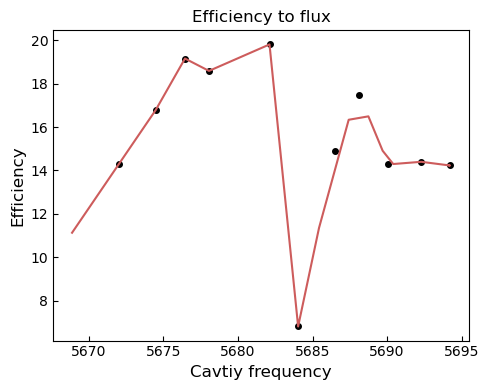

In [37]:
# Detector efficiency
flux_eff = [0, -0.3701923, -0.4230769, -0.4423077, -0.4519231, -0.4615385, -0.4663462, -0.4730769, -0.475, -0.4769231, -0.4788462]
eff = [14.23, 14.4, 14.28, 17.49, 14.92, 6.81, 19.81, 18.59, 19.16, 16.79, 14.31]

# flux_eff = [0, -0.3701923, -0.4230769, -0.4423077, -0.4519231, -0.4663462, -0.4730769, -0.475, -0.4769231, -0.4788462]
# eff = [14.23, 14.4, 14.28, 17.49, 14.92, 19.81, 18.59, 19.16, 16.79, 14.31]


eff_interpolate = interpolate.interp1d(freq_interpolate(flux_eff), eff, kind='linear',fill_value="extrapolate")
# f = np.linspace(flux[0], flux[-1], 4001)
ynew = eff_interpolate(storage_freq)

fig, ax = plt.subplots(figsize=(5,4))
ax1 = ax
ax1.plot(freq_interpolate(flux_eff), eff, 'o',markersize=4, linewidth=1, color = 'k');
ax1.plot(storage_freq, ynew, '-',markersize=4, linewidth=1.5, color = 'indianred');
ax1.set_xlabel(r'Cavtiy frequency', fontsize=12, fontname="DejaVu Sans");
ax1.set_ylabel(r'Efficiency', fontsize=12, fontname="DejaVu Sans");
ax1.set_title('Efficiency to flux')
plt.tight_layout();
plt.show()

In [38]:
freq_interpolate(-0.4423077)

array(5688.14304407)

In [59]:
-10*np.log10(np.sqrt(5.85e-3))

11.164220669589097

In [90]:
freq_interpolate(-0.4663462)

array(5682.11397877)

In [128]:
cavity_freq[9994]

5682.113999999955

# test reading data

In [39]:
def markovian(data, chi):
    # State reconstrution algorithms for the HMM

    # probability of possible state at i-th time step given all previous measurements
    def forward(meas_seq, T, E):
            # print("before forward:", T)
            num_meas = len(meas_seq)
            N = T.shape[0]
            alpha = zeros((num_meas, N))
            pi = [0.25,0.25,0.25,0.25] # assume flat prior
            alpha[0] = pi*E[:,meas_seq[0]]
            for t in range(1, num_meas):
                alpha[t] = alpha[t-1].dot(T) * E[:, meas_seq[t]]
            return alpha

    # probability of future measurements given state at i-th time step
    def backward(meas_seq, T, E):
            # print("before backward:", T)
            N = T.shape[0]
            num_meas = len(meas_seq)

            beta = zeros((N,num_meas))
            beta[:,-1:] = 1

            for t in reversed(range(num_meas-1)):
                for n in range(N):
                    beta[n,t] = sum(beta[:,t+1] * T[n,:] * E[:, meas_seq[t+1]])

            return beta
        
    def likelihood(meas_seq, T, E):
            # returns log P(Y  \mid  model)
            # using the forward part of the forward-backward algorithm
            # print("before likelihood:", T)
            return  forward(meas_seq, T, E)[-1].sum()

    # product of forward and backward probabilities
    # probability of state at i-th time step given the entire measurement record
    def gamma(meas_seq,T,E):
        alpha = forward(meas_seq, T, E)
        beta  = backward(meas_seq, T, E)
        obs_prob = likelihood(meas_seq, T, E)
        return (multiply(alpha,beta.T) / obs_prob)

    # returns the most likely state seqeunce given the measurement record
    # not used in this work
    def viterbi(meas_seq, T, E):
            # returns the most likely state sequence given observed sequence
            # using the Viterbi algorithm
            num_meas = len(meas_seq)
            N = T.shape[0]
            delta = zeros((num_meas, N))
            psi = zeros((num_meas, N))
            pi = [0.25,0.25,0.25,0.25]
            delta[0] = pi*E[:,meas_seq[0]]
            for t in range(1, num_meas):
                for j in range(N):
                    delta[t,j] = max(delta[t-1]*T[:,j]) * E[j, meas_seq[t]]
                    psi[t,j] = argmax(delta[t-1]*T[:,j])

            # backtrack
            states = zeros(num_meas, dtype=int32)
            states[num_meas-1] = argmax(delta[num_meas-1])
            for t in range(num_meas-2, -1, -1):
                states[t] = psi[t+1, states[t+1]]
            return states

    # device parameters

    trigger_period = 5 # all times in micro seconds
    parity_time = np.pi/(np.abs(chi)*2*pi)
    cav_t1 = 62.81 # caviy decay time
    qubit_t1 = 35.5 # qubit decay time
    qubit_t2 = 30.7 # qubit dephasing time
    # cav_n = 7.3e-4
    cav_n= 0.0
    qubit_n = 1.75e-2 # residual qubit population
    g_infidelity = 1-0.978 # infidelity of qubit g readout
    e_infidelity = 1-0.938 # infidelity of qubit e readout
    parity_err = 0

    # Defining transition and emission matricies for the hidden Markov model (HMM)

    P01 = cav_n * (1-exp(-trigger_period/cav_t1))
    P10 = 1-exp(-trigger_period/cav_t1)
    Pge = qubit_n * (1-exp(-trigger_period/qubit_t1)) + (1-exp(-parity_time/qubit_t2)) + parity_err
    Peg = (1-exp(-trigger_period/qubit_t1)) + (1-exp(-parity_time/qubit_t2)) + parity_err

    # print("parity_time: ", parity_time)

    T = None
    E = None

    T = asarray([[(1-P01)*(1-Pge), (1-P01)*Pge, P01*Pge, P01*(1-Pge)],
        [(1-P01)*Peg, (1-P01)*(1-Peg), P01*(1-Peg), P01*Peg],
        [P10*(1-Pge), P10*Pge, (1-P10)*Pge, (1-P10)*(1-Pge)],
        [P10*Peg, P10*(1-Peg), (1-P10)*(1-Peg), (1-P10)*Peg]])

    E = 0.5*asarray([[1-g_infidelity, g_infidelity],
        [e_infidelity, 1- e_infidelity],
        [1-g_infidelity, g_infidelity],
        [e_infidelity, 1- e_infidelity]])
    
    # print("initially", T)

    # want to compute the probabilities of 0 or 1 photon initially in the cavity
    P0_first = []
    P1_first = []

    # Use the HMM to determine the likelihood that a measurement sequence
    # is the result of a cavity photon present in the beginning

    start = 0
    stop = 25

    counts = len(data)

    thresh = 125

    state_list = data
    first_detected_state_list = []
    for ii in range (counts):
        meas_seq = state_list[ii][start:stop]
        # print(meas_seq)
        # print(np.shape(T))
        # print("before gamma:", T)
        gamma_matrix = gamma(meas_seq, T, E)

        P0 = gamma_matrix[0,0] + gamma_matrix[0,1]
        P1 = gamma_matrix[0,2] + gamma_matrix[0,3]

        # Compare the probabilities of the two models to obtain a likelihood ratio
        likelihood_ratio = P1/P0   
            
        if likelihood_ratio>thresh:
            first_detected_state_list.append(1)
        else:
            first_detected_state_list.append(0)
    first_count_count = sum(first_detected_state_list)


    return first_count_count

# Extract dark counts per cavity frequencies

In [353]:
file_no = np.arange(0, 12695, 1)
# file id=6840 is bad

file_no = np.arange(6841, 12695, 1)
dark_counts = []
cavity_freq = []
chi = []
for i in file_no:
     if i%100==0: print(i)
     nn = str(i).zfill(5)
     expt_path=os.getcwd()+'\data'
     prefix = "\\"+nn+"_Darkmatter_flux_tuning_data.h5"
     fname=expt_path+prefix

     with SlabFile(fname) as a:
          # print(np.array(a['cavity_freq'])[0])
          # flux_now = (a['yoko_current'][0]*1000-0.07)/2.08
          # print(flux_now)
          cavity_freq.append(np.array(a['cavity_freq'])[0])
          chi.append(double(chi_interpolate(freq2flux_interpolate(cavity_freq[-1]))))
          dict_list1 = parity_measurement_allocation(np.array(a['Idata'])[0], np.array(a['Qdata'])[0], np.array(a['parity_angle'])[0], np.array(a['parity_thre'])[0], np.array(a['cavity_freq'])[0], int(np.array(a['parity_number'])[0]))
          dark = markovian(dict_list1[np.array(a['cavity_freq'])[0]], chi[-1])
          dark_counts.append(dark)


6900
7000
7100
7200
7300
7400
7500
7600
7700
7800
7900
8000
8100
8200
8300
8400
8500
8600
8700
8800
8900
9000
9100
9200
9300
9400
9500
9600
9700
9800
9900
10000
10100
10200
10300
10400
10500
10600
10700
10800
10900
11000
11100
11200
11300
11400
11500
11600
11700
11800
11900
12000
12100
12200
12300
12400
12500
12600


In [40]:
file_no = np.arange(0, 1, 1)
# file id=6840 is bad

# file_no = np.arange(6841, 12695, 1)
dark_counts = []
cavity_freq = []
chi = []
for i in file_no:
     if i%100==0: print(i)
     nn = str(i).zfill(5)
     expt_path=os.getcwd()+'\data'
     prefix = "\\"+nn+"_Darkmatter_flux_tuning_data.h5"
     fname=expt_path+prefix

     with SlabFile(fname) as a:
          # print(np.array(a['cavity_freq'])[0])
          # flux_now = (a['yoko_current'][0]*1000-0.07)/2.08
          # print(flux_now)
          cavity_freq.append(np.array(a['cavity_freq'])[0])
          chi.append(double(chi_interpolate(freq2flux_interpolate(cavity_freq[-1]))))
          dict_list1 = parity_measurement_allocation(np.array(a['Idata'])[0], np.array(a['Qdata'])[0], np.array(a['parity_angle'])[0], np.array(a['parity_thre'])[0], np.array(a['cavity_freq'])[0], int(np.array(a['parity_number'])[0]))
          dark = markovian(dict_list1[np.array(a['cavity_freq'])[0]], chi[-1])
          dark_counts.append(dark)


0


In [46]:
with SlabFile(fname) as a:
    print(len(np.array(a['Idata'][0][0])))

20000


# save and load data

In [355]:
# save data, backup RAM to disk
np.save('cavity_freq_2',cavity_freq)
np.save('dark_counts_2',dark_counts)
np.save('chi_2',chi)

In [349]:
# save data, backup RAM to disk
np.save('cavity_freq_1',cavity_freq)
np.save('dark_counts_1',dark_counts)
np.save('chi_1',chi)

In [7]:
# load data from disk
cavity_freq1 = np.load('cavity_freq_1.npy')
dark_counts1 = np.load('dark_counts_1.npy')
chi1 = np.load('chi_1.npy')

In [8]:
# load data from disk
cavity_freq2 = np.load('cavity_freq_2.npy')
dark_counts2 = np.load('dark_counts_2.npy')
chi2 = np.load('chi_2.npy')

In [9]:
cavity_freq = np.concatenate((cavity_freq1,cavity_freq2))
dark_counts = np.concatenate((dark_counts1,dark_counts2))
chi = np.concatenate((chi1,chi2))

In [69]:
dark_counts[0]

18

In [70]:
min(dark_counts)

1

In [71]:
max(dark_counts)

91

In [29]:
dark_counts[-1]

29

In [23]:
cavity_freq[-1]-cavity_freq[0]

-22.824491065434813

In [31]:
chi[-1]

3.1512999999973963

In [34]:
cavity_freq2[0]

5686.680749882246

In [32]:
1000*T1_interpolate(cavity_freq[-1]/1000*1000)

64659.99999938368

In [27]:
chi_interpolate(freq2flux_interpolate(cavity_freq[0]/1000*1000))*0.001 

0.0033012772114710855

In [33]:
eff_interpolate(cavity_freq[-1]/1000*1000)/100

0.13661311685809055

# Hidden photon analysis

In [81]:
%matplotlib inline
from numpy import*
from pylab import*
import matplotlib.pyplot as plt
from h5py import File

#STIXGeneral

font = {'family' : 'STIXGeneral',
        'weight' : 'normal',
        'size'   : 22}

matplotlib.rc('font', **font)
# from slab.dsfit import*
# from slab import*
import json

from qutip import*
from scipy.special import gamma, loggamma
from scipy.stats import binom
from tqdm import tqdm

In [82]:
def powspace(start, stop, power, num):
    start = np.power(start, 1/float(power))
    stop = np.power(stop, 1/float(power))
    return np.power( np.linspace(start, stop, num=num), power) 

## Tuner parameter

In [29]:
no = len(cavity_freq)
exclusion_results = []
for i in tqdm(range(no)):
    # if i%100==0: print(i)

    Q_dm = 1e6
    nu_c = cavity_freq[i]/1000 #GHz
    sigma_nu_c = 0.0001
    nu_q = 4.8116 #GHz   Average of all tuning points
    n_q = 0.014
    n_q_err = 0.002
    T1_c = 1000*T1_interpolate(nu_c*1000) #us*1e9  linear extrapolating tuning data
    sigma_T1_c = 0.2574e3 #us*1e9  Cavity T1 error, from fitting
    Q_c = T1_c * nu_c * 2*pi
    sigma_Q_c = sqrt((2*pi*T1_c*sigma_nu_c)**2 + (2*pi*nu_c*sigma_T1_c)**2)
    twochi = chi_interpolate(freq2flux_interpolate(nu_c*1000))*0.001 #GHz    cubic extrapolating tuning data
    alpha = 176.7973e-3 #GHz average value from tuning data
    g = sqrt(0.5*twochi*(nu_c-nu_q)/alpha* (nu_c-nu_q+alpha))
    l_c = 1.4 * 0.0254 #meter, remember to check the design
    w_c = 1.5* 0.0254
    h_c = 0.1875* 0.0254
    sigma_dim = 0.005 * 0.0254 #estimated machining tolerance in meters
    V_c = l_c*w_c*h_c #m^3
    sigma_V_c = sigma_dim*sqrt((l_c*w_c)**2 + (l_c*h_c)**2 + (w_c*h_c)**2)

    T1_q = 34.436e3    # average value from tuning data
    T2_q = 32.059e3    # average value from tuning data
    kappa = 1/T1_c
    gamma2 = 1/(T2_q)
    twochi = -chi_interpolate(freq2flux_interpolate(nu_c*1000))*0.001 #GHz
    chi = twochi/2

    # nu_c_old = 6.0112753038219+chi #GHz

    nu_c += chi #GHz


    G = 2**6/(pi**4) #Electric form factor
    sigma_G = 0.01
    Gavg = 1/3 #avg of DP field over all directions
    rho_dm = 2*pi*1.09e20 #2pi*GHz/m^3, using 0.45GeV/cm^3

    v_0 = 220e3/(3e8)
    v_obs = 232e3/(3e8)


    def N_HP(epsilon, nu, N_meas):
        return epsilon**2*rho_dm*Q_dm*Q_c*G*Gavg*V_c*N_meas/(2*pi*nu)

    def eps(n_th, nu):
        return sqrt (2*pi*nu * n_th/((Q_dm*Q_c)*G*Gavg*V_c*rho_dm))

    # including detector efficiency as nuisance parameter. integrate over gaussian distributed parameter
    # determine n_HP exluded with 90% confidence
    # Asking the question, what HP population, detected with uncertain efficiency, cavity freq, cavity Q, etc...
    # could result in the observed N counts with >90% confidence.

    N_meas = 20000    # remember to update this value
    N_obs = dark_counts[i]
    eta = eff_interpolate(nu_c*1000)/100    # use linear extrapolating data
    sigma_eta = 0.0212   # 1 sigma form the measured threshold
    eps_test = linspace(3e-15,3e-14, 501)
    Rp = 10

    #generate test values for each parameter
    N_values = 11
    #detection efficiency
    eta_test_list, eta_step = linspace((1-5*sigma_eta/eta)*eta, (1+5*sigma_eta/eta)*eta, num=N_values, retstep=True)
    # gauss = 1/(sqrt(2*pi)*sigma_eta) * exp(-(eta-eta_test_list)**2/(2*sigma_eta**2))
    # gauss_sum = sum(gauss)
    # plot(eta_test_list, gauss/sum(gauss), '.')

    #cavity frequency
    nu_c_test_list, nu_c_step = linspace((1-3*sigma_nu_c/nu_c)*nu_c, (1+3*sigma_nu_c/nu_c)*nu_c, num=N_values, retstep=True)

    #cavity quality factor
    Q_c_test_list, Q_c_step = linspace((1-3*sigma_Q_c/Q_c)*Q_c, (1+3*sigma_Q_c/Q_c)*Q_c, num=N_values, retstep=True)

    #cavity volume
    V_c_test_list, V_c_step = linspace((1-3*sigma_V_c/V_c)*V_c, (1+3*sigma_V_c/V_c)*V_c, num=N_values, retstep=True)

    #overlap factor
    G_test_list, G_step = linspace((1-3*sigma_G/G)*G, (1+3*sigma_G/G)*G, num=N_values, retstep=True)

    running_sum = 0
    for eta_test in eta_test_list:
        for Q_c_test in Q_c_test_list:
            for nu_c_test in nu_c_test_list:
                for V_c_test in V_c_test_list:
                    for G_test in G_test_list:
                        Na_test = eps_test**2*rho_dm*Q_dm*Q_c_test*G_test*Gavg*V_c_test*N_meas/(2*pi*nu_c_test)
                        running_sum  += binom.cdf(N_obs, N_meas, eta_test*Na_test/N_meas) \
                        * 1/(sqrt(2*pi)*sigma_eta) * exp(-(eta-eta_test)**2/(2*sigma_eta**2)) * eta_step \
                        * 1/(sqrt(2*pi)*sigma_nu_c) * exp(-(nu_c-nu_c_test)**2/(2*sigma_nu_c**2)) * nu_c_step \
                        * 1/(sqrt(2*pi)*sigma_Q_c) * exp(-(Q_c-Q_c_test)**2/(2*sigma_Q_c**2)) * Q_c_step \
                        * 1/(sqrt(2*pi)*sigma_V_c) * exp(-(V_c-V_c_test)**2/(2*sigma_V_c**2)) * V_c_step \
                        * 1/(sqrt(2*pi)*sigma_G) * exp(-(G-G_test)**2/(2*sigma_G**2)) * G_step
    cumul = binom.cdf(N_obs, N_meas, eta*N_HP(eps_test, nu_c, N_meas)/N_meas)
    # my_dpi=72
    # figure(figsize = (8,3))
    # semilogy(eps_test, running_sum, lw=5)
    # plot(eps_test, cumul, label='original analysis')
    # axhline(0.1, alpha=0.25, color = 'purple', lw = 3, ls='dashed', label = 'P = 10%')
    # ylim(1e-4,1.1)
    # #xlim(0,2)
    # xlabel('Hidden photon mixing angle')
    # ylabel('Cumulative probability')
    # legend()

    eps_HP_90 = (eps_test[argmin(abs(1/running_sum-Rp))])
    # axvline(eps_HP_90, alpha = 0.5, color='r', ls='dashed', lw=3)

    # N_HP_90 = N_HP(epsilon = eps_HP_90, nu = nu_c, N_meas = N_meas)
    # print(eps_HP_90)
    # grid(axis='x')
    # # savefig('eps_exclusion.pdf', dpi=my_dpi)
    # print(N_HP_90)
    exclusion_results.append(eps_HP_90)


  0%|          | 0/12695 [00:00<?, ?it/s]

100%|█████████▉| 12694/12695 [128:08:33<00:36, 36.34s/it]   


IndexError: index 12694 is out of bounds for axis 0 with size 12694

In [31]:
np.save('exclusion_results.npy',exclusion_results)

In [248]:
# save data, backup RAM to disk
np.save('exclusion_results',exclusion_results)


0.14375481970111706

In [19]:
exclusion_results=np.load('exclusion_results.npy')

FileNotFoundError: [Errno 2] No such file or directory: 'exclusion_results.npy'

In [119]:
exclusion_results[9079]

3.7559999999999995e-15

In [118]:
np.argmin(exclusion_results)

9079

([<matplotlib.axis.XTick at 0x2068001b040>,
 [Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, '')])

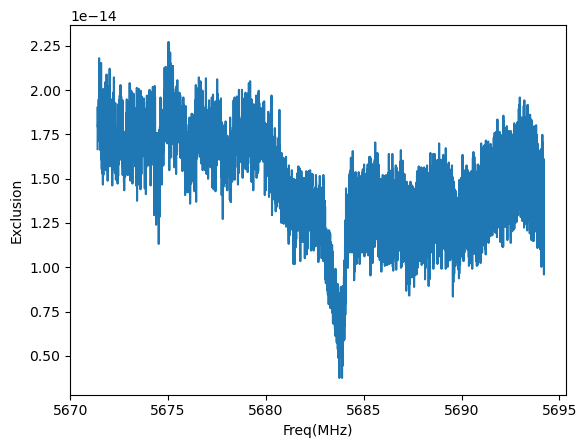

In [35]:
plt.plot(cavity_freq[0:-1], exclusion_results,'-')
# plt.yscale('log')
plt.xlabel('Freq(MHz)')
plt.ylabel('Exclusion')
plt.xticks(np.arange(5670, 5700, 5))

([<matplotlib.axis.XTick at 0x2068020c670>,
 [Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, '')])

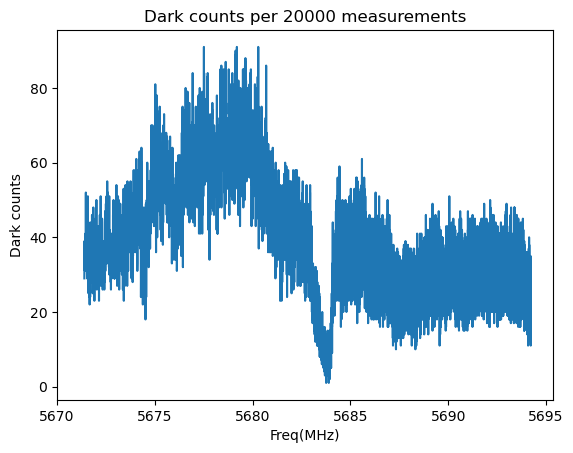

In [36]:
plt.plot(cavity_freq[0:-1], dark_counts)
plt.xlabel('Freq(MHz)')
plt.ylabel('Dark counts')
plt.title('Dark counts per 20000 measurements')
plt.xticks(np.arange(5670, 5700, 5))

# Combined output

In [38]:
bound1_freq = np.load('bound1_freq.npy')
bound2_freq = np.load('bound2_freq.npy')
bound_ep1 = np.load('bound1_epsilon.npy')
bound_ep2 = np.load('bound2_epsilon.npy')

In [ ]:
exclusion_results_new = np.load('exclusion_results_new.npy')
exclusion_results = np.load('exclusion_results.npy')

start_index = 6994 # The starting index in a where you want to insert b
end_index = start_index + len(exclusion_results_new)  # The end index will depend on the length of b

# Replace the specified range in a with b
exclusion_results[start_index:end_index] = exclusion_results_new

FileNotFoundError: [Errno 2] No such file or directory: 'exclusion_results_new.npy'

In [51]:
np.argmin(bound_ep1)

1448

In [52]:
np.argmin(bound_ep2)

2221

([<matplotlib.axis.XTick at 0x20688a33f10>,
 [Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, '')])

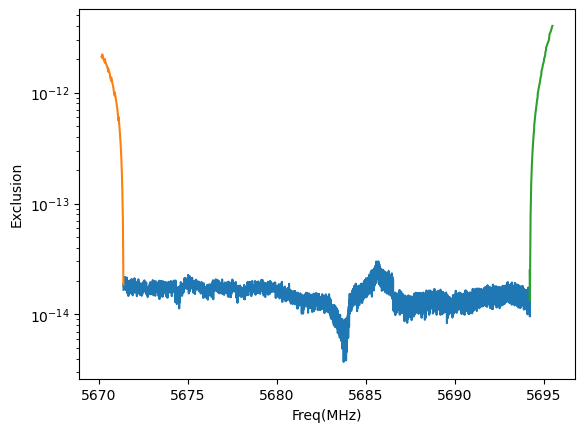

In [136]:
plt.plot(cavity_freq[0:-1], exclusion_results,'-')
plt.plot(bound2_freq[:2222]*1e3, bound_ep2[:2222],'-')
plt.plot(bound1_freq[-1448:]*1e3, bound_ep1[-1448:],'-')
plt.yscale('log')
# plt.ylim([0,1e-13])
plt.xlabel('Freq(MHz)')
plt.ylabel('Exclusion')
plt.xticks(np.arange(5670, 5700, 5))

([<matplotlib.axis.XTick at 0x206906c4c10>,
 [Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, '')])

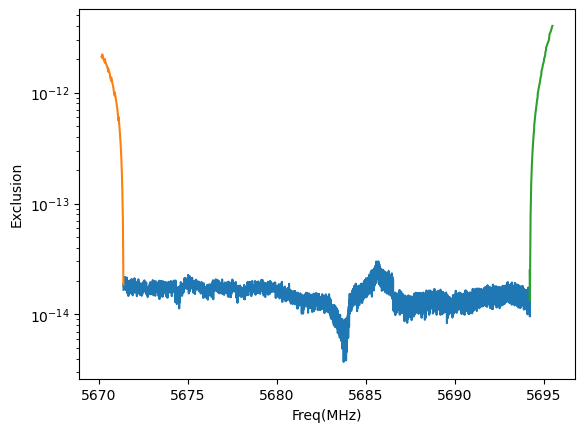

In [151]:
plt.plot(cavity_freq[0:-1], exclusion_results,'-')
plt.plot(bound2_freq[:2222]*1e3, bound_ep2[:2222],'-')
plt.plot(bound1_freq[-1448:]*1e3, bound_ep1[-1448:],'-')
plt.yscale('log')
# plt.ylim([0,1e-13])
plt.xlabel('Freq(MHz)')
plt.ylabel('Exclusion')
plt.xticks(np.arange(5670, 5700, 5))

# Plot final result (modify this)

In [152]:
result_freq = cavity_freq[0:-1]
result_exclusion = exclusion_results
np.save('hidden_photon_freq_1.npy', result_freq)
np.save('hidden_photon_result_1.npy', result_exclusion)

In [174]:
arr = bound1_freq[-1448:]*1e3
reversed_arr = arr[::-1]
result_freq1 = np.concatenate([reversed_arr, cavity_freq[0:-1], bound2_freq[:2222]*1e3])
arr = bound_ep1[-1448:]
reversed_arr = arr[::-1]
result_exclusion1 = np.concatenate([reversed_arr, exclusion_results, bound_ep2[:2222]])
np.save('hidden_photon_freq_2.npy', result_freq1)
np.save('hidden_photon_result_2.npy', result_exclusion1)

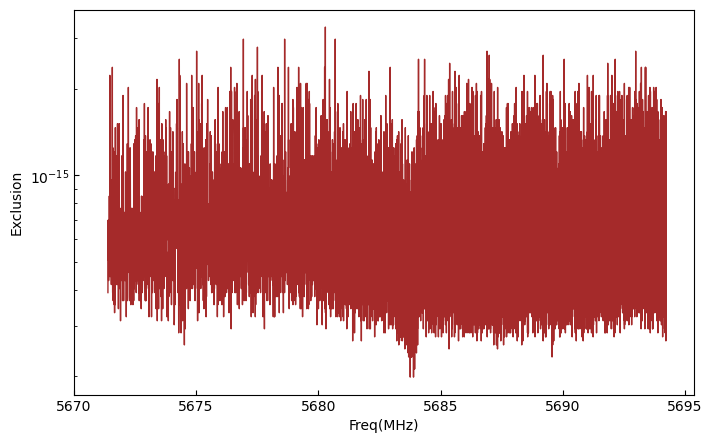

In [4]:
result_freq = np.load('cavity_freq_new.npy')
result_exclusion = np.load('exclusion_results_07012025.npy')
dark_counts = np.load('dark_counts_new.npy')
fig = plt.figure(figsize=(8,5))
plt.rcParams['xtick.direction'] = 'in'  
plt.rcParams['ytick.direction'] = 'in'
plt.plot(result_freq, result_exclusion,'-',linewidth=1, color='brown')
plt.yscale('log')
# plt.ylim([0,1e-13])

plt.xlabel('Freq(MHz)')
plt.ylabel('Exclusion')
plt.xticks(np.arange(5670, 5700, 5))
plt.savefig('hidden_photon1_revised.pdf')

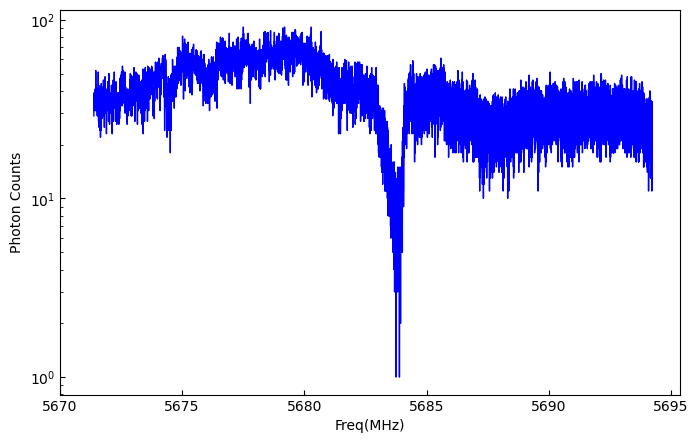

In [5]:
# result_freq = np.load('hidden_photon_freq_1.npy')
# result_exclusion = np.load('hidden_photon_result_1.npy')
fig = plt.figure(figsize=(8,5))
plt.rcParams['xtick.direction'] = 'in'  
plt.rcParams['ytick.direction'] = 'in'
plt.plot(result_freq, dark_counts,'-',linewidth=1, color='blue')
plt.yscale('log')
# plt.ylim([0,1e-13])

plt.xlabel('Freq(MHz)')
plt.ylabel('Photon Counts')
plt.xticks(np.arange(5670, 5700, 5))
plt.savefig('hidden_photon3_revised.pdf')

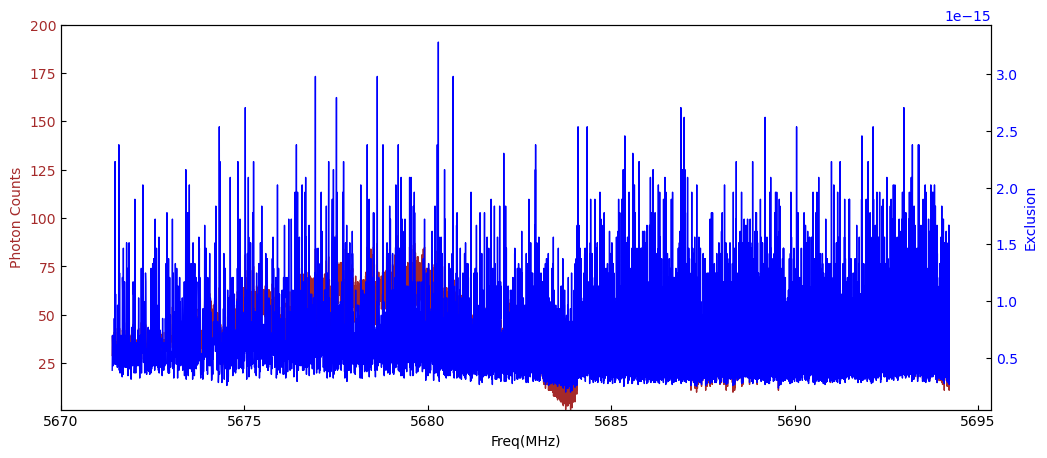

In [7]:
# Sample data
x = range(1, 11)
y1 = [2*n + 1 for n in x]  # Example data for the first plot
y2 = [3*n + 1.5 for n in x]  # Example data for the second plot

fig, ax1 = plt.subplots(figsize=(12,5))
plt.rcParams['xtick.direction'] = 'in'  
plt.rcParams['ytick.direction'] = 'in'

# Creating the first line plot on the left y-axis
ax1.plot(result_freq, dark_counts,'-',linewidth=1, color='brown')  # 'g-' sets the color of the line to green
ax1.set_xlabel('Freq(MHz)')
ax1.set_ylabel('Photon Counts', color='brown')
ax1.tick_params(axis='y', labelcolor='brown')
ax1.set_ylim(1,200)
# ax1.set_yscale('log')

# Creating a second axes that shares the same x-axis
ax2 = ax1.twinx()
# ax2.set_yscale('log')
ax2.plot(result_freq, result_exclusion,'-',linewidth=1, color='blue')  # 'b-' sets the color of the line to blue
ax2.set_ylabel('Exclusion', color='b')
ax2.tick_params(axis='y', labelcolor='b')


# plt.xlabel('Freq(MHz)')
# plt.ylabel('Exclusion')
plt.xticks(np.arange(5670, 5700, 5))

plt.savefig('hidden_photon1_revised.pdf')

In [32]:
freq2flux_interpolate(5694.212491065196)

array(0.02637071)

In [34]:
freq2flux_interpolate(5671.395223306798)

array(-0.47932152)

In [52]:
1/6.72*1e3

148.8095238095238

In [51]:
-10*log10(np.sqrt(6.72*1e-3))

10.863153634730873

In [46]:
(freq_interpolate(-0.4793215)-freq_interpolate(-0.4793215-4.807692307692308e-06))

0.007220223214972066

In [3]:
import numpy as np
from matplotlib import pyplot as plt
result_freq = np.load('hidden_photon_freq_1.npy')

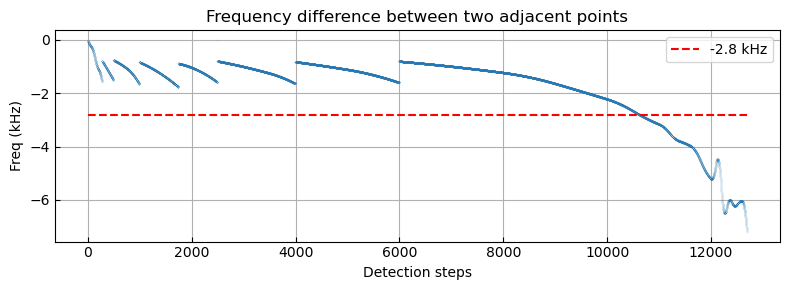

In [8]:
fig = plt.figure(figsize=(8,3))
plt.grid()
plt.plot(np.diff(result_freq)*1000,'.',markersize=0.1, rasterized=True)
plt.hlines(y=-2.8, xmin=0, xmax=len(result_freq), color='r', linestyle='--', label='-2.8 kHz')
plt.title('Frequency difference between two adjacent points')
plt.ylabel('Freq (kHz)')
plt.xlabel('Detection steps')
plt.legend()
plt.tight_layout()
# plt.savefig('freq_diff.pdf')
# plt.yscale('log')

# Plot updated mixing angle exclusion data

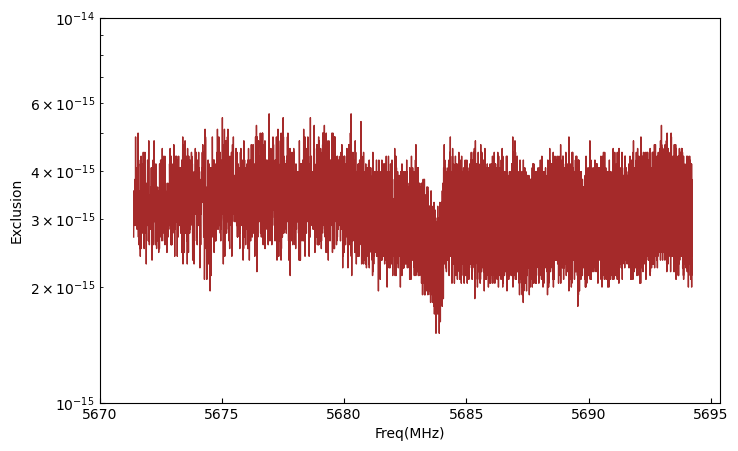

In [7]:
result_freq = np.load('cavity_freq_new.npy')
result_exclusion = np.load('exclusion_results_07012025.npy')
dark_counts = np.load('dark_counts_new.npy')
fig = plt.figure(figsize=(8,5))
plt.rcParams['xtick.direction'] = 'in'  
plt.rcParams['ytick.direction'] = 'in'
plt.plot(result_freq, result_exclusion,'-',linewidth=1, color='brown')
plt.yscale('log')
plt.ylim([1e-15, 1e-14])
# plt.ylim([0,1e-13])

plt.xlabel('Freq(MHz)')
plt.ylabel('Exclusion')
plt.xticks(np.arange(5670, 5700, 5))
plt.savefig('hidden_photon1_revised.pdf')

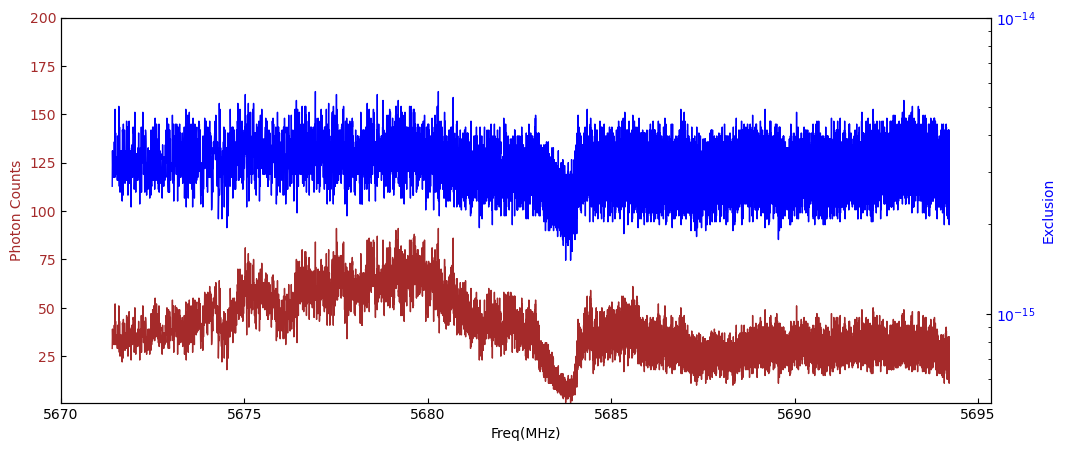

In [8]:
# Sample data
x = range(1, 11)
y1 = [2*n + 1 for n in x]  # Example data for the first plot
y2 = [3*n + 1.5 for n in x]  # Example data for the second plot

fig, ax1 = plt.subplots(figsize=(12,5))
plt.rcParams['xtick.direction'] = 'in'  
plt.rcParams['ytick.direction'] = 'in'

# Creating the first line plot on the left y-axis
ax1.plot(result_freq, dark_counts,'-',linewidth=1, color='brown')  # 'g-' sets the color of the line to green
ax1.set_xlabel('Freq(MHz)')
ax1.set_ylabel('Photon Counts', color='brown')
ax1.tick_params(axis='y', labelcolor='brown')
ax1.set_ylim(1,200)
# ax1.set_yscale('log')

# Creating a second axes that shares the same x-axis
ax2 = ax1.twinx()
# ax2.set_yscale('log')
ax2.plot(result_freq, result_exclusion,'-',linewidth=1, color='blue')  # 'b-' sets the color of the line to blue
ax2.set_ylabel('Exclusion', color='b')
ax2.tick_params(axis='y', labelcolor='b')
ax2.set_yscale('log')
ax2.set_ylim([5e-16, 1e-14])


# plt.xlabel('Freq(MHz)')
# plt.ylabel('Exclusion')
plt.xticks(np.arange(5670, 5700, 5))

plt.savefig('hidden_photon2_revised.pdf')

In [9]:
max(result_exclusion)

5.623413251903491e-15

In [10]:
min(result_exclusion)

1.5135612484362072e-15

# revision2 add dm_exclusion_scale

In [14]:
from tqdm import tqdm

In [15]:
result_freq = np.load('cavity_freq_new.npy')
result_exclusion = np.load('exclusion_results_07012025.npy')
dark_counts = np.load('dark_counts_new.npy')

In [37]:
def dm_exclusion_scaled(cavity_freq, epsilon):
    
    freq_list = []
    epsilon_list = []

    f_range = 0.001
    for freq in (cavity_freq):
        f_drive = linspace(freq - 5*f_range, freq - 1*f_range, 10)
        freq_list.extend(f_drive)
        
    for jj, freq in enumerate(tqdm(cavity_freq)):
    
        # f_range = 0.001
        # f_drive = linspace(freq - 5*f_range, freq - 1*f_range, 100)

        v_0 = 220e3/(3e8)
        v_obs = 232e3/(3e8)

        v = []
        for ii in range(len(freq_list)):
            v_temp_squared = 2 * ((freq/freq_list[ii])-1)
            if v_temp_squared < 0:
                v.append(0)
            elif sqrt(v_temp_squared) > 1:
                v.append(0)
            else:
                v.append(sqrt(v_temp_squared))

        v = asarray(v)

    #     figure()
    #     plot(f_drive,v)


    #     figure()

        f_v = v/(sqrt(pi)*v_0*v_obs) * exp(-((v+v_obs)/v_0)**2) * exp(4*v*v_obs/v_0**2-1)
        f_v = (f_v)/max((f_v))
        
        # freq_list.extend(f_drive)
        epsilon_list.append(1/f_v*epsilon[jj])

    epsilon_list = asarray(epsilon_list)
    eps_list_new = []
    for ii in range(len(epsilon_list.T)):
        eps_list_new.append(min(epsilon_list.T[ii]))
        
    return freq_list, asarray(eps_list_new)

In [69]:
def dm_exclusion_scaled_zoomed(cavity_freq, epsilon):
    
    freq_list = []
    epsilon_list = []
    for jj, freq in enumerate(tqdm(cavity_freq)):
    
        f_range = 0.001
        f_drive = linspace(freq - 10*f_range, freq + 0.01*f_range, 100)

        v_0 = 220e3/(3e8)
        v_obs = 232e3/(3e8)

        v = []
        for ii in range(len(f_drive)):
            v_temp_squared = 2 * ((freq/f_drive[ii])-1)
            if v_temp_squared < 0:
                v.append(0)
            elif sqrt(v_temp_squared) > 1:
                v.append(0)
            else:
                v.append(sqrt(v_temp_squared))

        v = asarray(v)

    #     figure()
    #     plot(f_drive,v)


    #     figure()

        f_v = v/(sqrt(pi)*v_0*v_obs) * exp(-((v+v_obs)/v_0)**2) * exp(4*v*v_obs/v_0**2-1)
        f_v = (f_v)/max((f_v))
        
        freq_list.extend(f_drive)
        epsilon_list.extend(1/f_v*epsilon[jj])
    return freq_list, epsilon_list

In [38]:
freq_list, epsilon_list = dm_exclusion_scaled(result_freq, result_exclusion)

  0%|          | 0/12694 [00:00<?, ?it/s]C:\Users\26049\AppData\Local\Temp\ipykernel_28892\3902049531.py:41: RuntimeWarning: divide by zero encountered in divide
  epsilon_list.append(1/f_v*epsilon[jj])
100%|██████████| 12694/12694 [35:21<00:00,  5.98it/s] 


In [40]:
np.save('hidden_photon_freq_smoothed.npy', freq_list)
np.save('hidden_photon_result_smoothed.npy', epsilon_list)

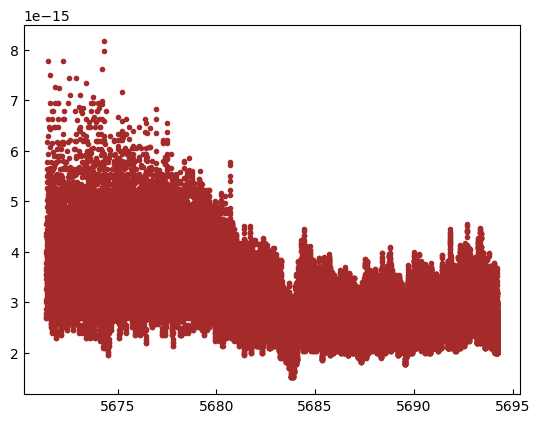

In [52]:
plt.plot(freq_list, epsilon_list, '.', linewidth=1, color='brown')

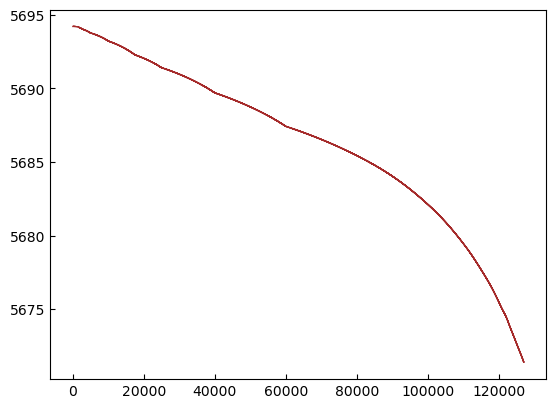

In [53]:
plt.plot(freq_list, '-', linewidth=1, color='brown')

In [94]:
freq_list_zoomed, epsilon_list_zoomed = dm_exclusion_scaled_zoomed(result_freq[0:50], result_exclusion[0:50])

  0%|          | 0/50 [00:00<?, ?it/s]C:\Users\26049\AppData\Local\Temp\ipykernel_28892\1238605626.py:35: RuntimeWarning: divide by zero encountered in divide
  epsilon_list.extend(1/f_v*epsilon[jj])
100%|██████████| 50/50 [00:00<00:00, 5325.83it/s]


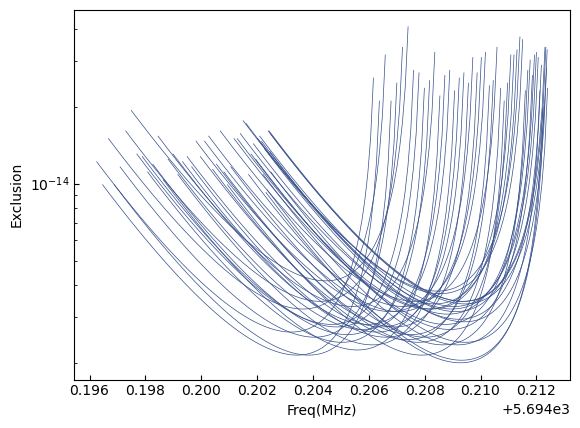

In [100]:
for i in range(len(freq_list_zoomed)//100):
    x = freq_list_zoomed[i*100:(i+1)*100]
    y = epsilon_list_zoomed[i*100:(i+1)*100]
    plt.plot(x, y, '-', color='#354e8b', linewidth=0.5)
plt.xlabel('Freq(MHz)')
plt.ylabel('Exclusion')
plt.yscale('log')
out = Path.home() / "Desktop" / "hidden_photon_zoomed.pdf"
plt.savefig(out)

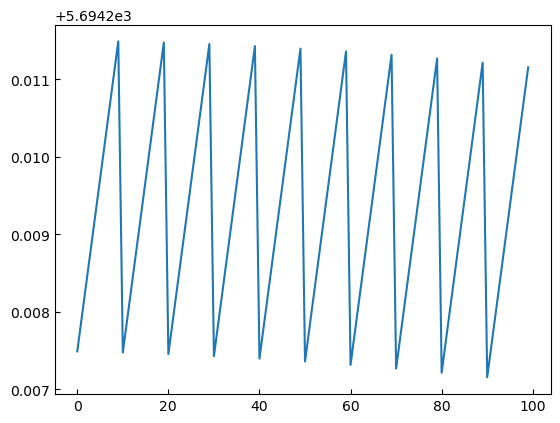

In [79]:
plt.plot(x)

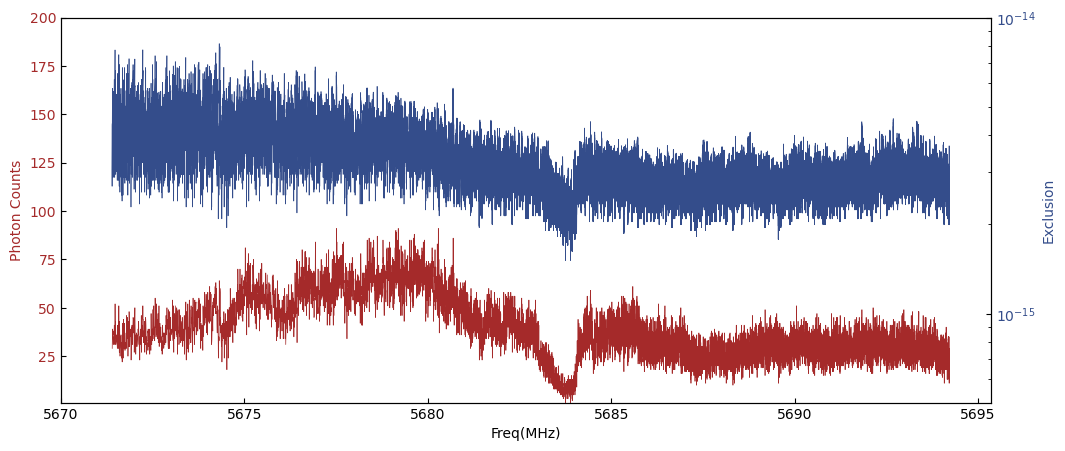

In [63]:
from pathlib import Path
# Sample data
x = range(1, 11)
y1 = [2*n + 1 for n in x]  # Example data for the first plot
y2 = [3*n + 1.5 for n in x]  # Example data for the second plot

fig, ax1 = plt.subplots(figsize=(12,5))
plt.rcParams['xtick.direction'] = 'in'  
plt.rcParams['ytick.direction'] = 'in'

# Creating the first line plot on the left y-axis
ax1.plot(result_freq, dark_counts,'-',linewidth=0.5, color='brown')  # 'g-' sets the color of the line to green
ax1.set_xlabel('Freq(MHz)')
ax1.set_ylabel('Photon Counts', color='brown')
ax1.tick_params(axis='y', labelcolor='brown')
ax1.set_ylim(1,200)
# ax1.set_yscale('log')

# Creating a second axes that shares the same x-axis
ax2 = ax1.twinx()
# ax2.set_yscale('log')
ax2.plot(freq_list, epsilon_list,'-',linewidth=0.5, color='#344d8b')  # 'b-' sets the color of the line to blue
ax2.set_ylabel('Exclusion', color='#344d8b')
ax2.tick_params(axis='y', labelcolor='#344d8b')
ax2.set_yscale('log')
ax2.set_ylim([5e-16, 1e-14])


# plt.xlabel('Freq(MHz)')
# plt.ylabel('Exclusion')
plt.xticks(np.arange(5670, 5700, 5))
out = Path.home() / "Desktop" / "hidden_photon_smoothed_revised.pdf"
plt.savefig(out)

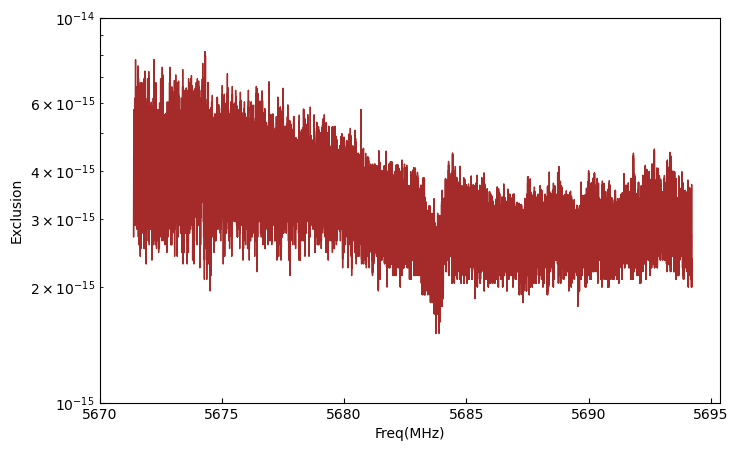

In [68]:


fig = plt.figure(figsize=(8,5))
plt.rcParams['xtick.direction'] = 'in'  
plt.rcParams['ytick.direction'] = 'in'
plt.plot(freq_list, epsilon_list,'-',linewidth=1, color='brown')
plt.yscale('log')
plt.ylim([1e-15, 1e-14])
# plt.ylim([0,1e-13])

plt.xlabel('Freq(MHz)')
plt.ylabel('Exclusion')
plt.xticks(np.arange(5670, 5700, 5))
out = Path.home() / "Desktop" / "hidden_photon_smoothed_only_exclusion.pdf"
plt.savefig(out)

In [55]:
fname = 'hidden_photon_smoothed_revised.pdf'
print(repr(fname)) 

'hidden_photon_smoothed_revised.pdf'


In [56]:
import os, pathlib
print(os.getcwd())
pathlib.Path('.').touch('._write_test.tmp')  # should succeed

g:\My Drive\my projects\PhD\darkmatter\revision


In [44]:
max(epsilon_list)

8.162229579385442e-15

In [45]:
min(epsilon_list)

1.5135612484362072e-15